# Машинное обучение, ФКН ВШЭ

# Практическое задание 9. Рекомендательные системы

## Общая информация

**Дата выдачи: 08.10.2026**

**Мягкий дедлайн: 25.10.2026 23:59 MSK**

**Жёсткий дедлайн: 08.11.2026 23:59 MSK**

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу – **10** баллов за основную часть + **1.5** бонусных.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:

* Ноутбук homework-practice-09-Username.ipynb

Username – ваша фамилия и имя на латинице именно в таком порядке

## О задании

В этой работе мы будем решать задачу рекомендации музыки (звуууук). То есть мы поставим целью получить модель, которая для каждого пользователя будет возвращать набор треков, наиболее похожих на те, что он уже слушал. В первой части мы разберемся с memory-based подходом и моделью со скрытыми переменными. Это не очень мощные методы, но зато они позволяют строить предсказания почти моментально. Затем, во второй части, мы обратим внимание на то, что датасет содержит огромное число треков и воспользуемся результатами уже построенных быстрых моделей для сокращения списка кандидатов до разумного количества. После этого проведем ранжирование среди кандидатов с помощью сильной, но чуть более медленной модели, и отберем самые лучшие варианты. Такой двухэтапный алгоритм построения рекомендаций изображен на картинке.


![](https://i.ibb.co/4RptSVjp/Screenshot-2026-03-23-at-00-29-18.png)

Приступим!

Все шаблоны ниже можно переписывать по своему усмотрению.

In [1]:
from sklearn.preprocessing import LabelEncoder

import pandas as pd
import numpy as np
from tqdm import tqdm
from typing import Callable, List

import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as scs

In [2]:
ratings = pd.read_csv('music_dataset.csv')
ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [3]:
ratings.columns

Index(['userId', 'trackId'], dtype='str')

In [4]:
tracks_info = pd.read_csv('tracks_info.csv')
tracks_info.head()

,id,name,artists
0,0,What There Is,['a-ha']
1,1,I'll Play The Blues For You,['Albert King']
2,2,Breaking Up Somebody's Home,['Albert King']
3,3,Imma Be,['Black Eyed Peas']
4,4,Boom Boom Pow,['Black Eyed Peas']


In [5]:
tracks_info.columns

Index(['id', 'name', 'artists'], dtype='str')

Для оценки качества рекомендаций мы будем использовать метрику $MAP@k$.

$$
MAP@k = \frac{1}{N} \sum_{u = 1}^N AP_u@k
$$
$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)$$


*   $N$ - количество пользователей.
*   $n_u$ - число релевантных треков пользователя $u$ на тестовом промежутке.
*   $r_u(i)$ - бинарная величина: относится ли трек на позиции $i$ к релевантным.

**Задание 1 (0.5 балл).** Реализуйте метрику $MAP@k$.

In [6]:
def mapk(relevant: List[List[int]], predicted: List[List[int]], k: int = 20):
    # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
    ap_list = []
    
    for true_items, pred_items in zip(relevant, predicted):
        pred_items = pred_items[:k]
        n_u = len(true_items)
        
        if n_u == 0 or len(pred_items) == 0:
            ap_list.append(0.0)
            continue
            
        true_set = set(true_items)
        count_tracks = 0
        full_sum = 0.0
        
        for idx, value in enumerate(pred_items):
            if value in true_set:
                count_tracks += 1
                full_sum += count_tracks / (idx + 1)
                
        norm = min(k, n_u)
        ap_list.append(full_sum / norm)
        
    return np.mean(ap_list)
            
        

In [7]:
relevant = [
    [1, 7, 6, 2, 8],
    [1, 5, 4, 8],
    [8, 2, 5]
]

pred = [
    [8, 1, 5, 0, 7, 2, 9, 4],
    [0, 1, 8, 5, 3, 4, 7, 9],
    [9, 2, 0, 6, 8, 5, 3, 7]
]

assert round(mapk(relevant, pred, k=5), 4) == 0.4331

Отложим 50 последних строк каждого пользователя, остальные оставим для обучения. В данных нет времени прослушивания, поэтому это не временное разбиение.

Отложенные данные разделим по пользователям: на валидацию, обучение ранкера и финальный тест. В частях 1-2 параметры подбирайте по валидации.

In [8]:
def train_test_split(ratings):
    train_ratings, test_ratings = [], []
    num_test_samples = 50

    for userId, user_data in tqdm(ratings.groupby('userId')):
        train_ratings += [user_data[:-num_test_samples]]

    train_ratings = pd.concat(train_ratings).reset_index(drop=True)
    all_train_items = train_ratings['trackId'].unique()

    # getting train samples
    # we drop all tracks that are not presented it the training samples,
    # because we won't be able to learn representations for them
    for userId, user_data in tqdm(ratings.groupby('userId')):
        test_items = user_data[-num_test_samples:]
        test_items = test_items[np.isin(test_items['trackId'], all_train_items)]
        test_ratings += [test_items]

    test_ratings = pd.concat(test_ratings).reset_index(drop=True)

    return train_ratings, test_ratings

In [9]:
from sklearn.model_selection import train_test_split as split_users

train_ratings, holdout_ratings = train_test_split(ratings)

rank_test_users, valid_users = split_users(
    np.sort(holdout_ratings['userId'].unique()), test_size=0.2, random_state=42
)
rank_train_users, final_test_users = split_users(
    rank_test_users, test_size=0.4, random_state=42
)
rank_train_users = np.sort(rank_train_users)
valid_users = np.sort(valid_users)
final_test_users = np.sort(final_test_users)

rank_train_ratings = holdout_ratings[holdout_ratings['userId'].isin(rank_train_users)].copy()
test_ratings = holdout_ratings[holdout_ratings['userId'].isin(valid_users)].copy()
final_test_ratings = holdout_ratings[holdout_ratings['userId'].isin(final_test_users)].copy()

  0%|          | 0/241 [00:00<?, ?it/s]

100%|██████████| 241/241 [00:00<00:00, 1490.15it/s]


Почистим табличку с информацией о треках и закодируем id треков так, чтобы они соответствовали их порядковому номеру.

In [10]:
redundant_rows = np.where(~np.isin(tracks_info['id'], train_ratings['trackId'].unique()))[0]
tracks_info.drop(redundant_rows, inplace=True)
tracks_info = tracks_info.reset_index(drop=True)

In [11]:
def ids_encoder(ratings):
    users = sorted(ratings['userId'].unique())
    items = sorted(ratings['trackId'].unique())

    # create users and items encoders
    uencoder = LabelEncoder()
    iencoder = LabelEncoder()

    # fit users and items ids to the corresponding encoder
    uencoder.fit(users)
    iencoder.fit(items)

    return uencoder, iencoder

In [12]:
uencoder, iencoder = ids_encoder(train_ratings)
for frame in (train_ratings, test_ratings, rank_train_ratings, final_test_ratings):
    frame['trackId'] = iencoder.transform(frame['trackId'].tolist())
tracks_info['id'] = iencoder.transform(tracks_info['id'].tolist())

In [13]:
train_ratings.head()

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404


In [14]:
test_ratings.head()

,userId,trackId
238,9,36055
239,9,36056
240,9,36058
241,9,36063
242,9,36139


Соберем все релевантные треки для каждого пользователя в список.

In [15]:
test_relevant = []
test_users = []
for user_id, user_data in test_ratings.groupby('userId'):
    test_relevant += [user_data['trackId'].tolist()]
    test_users.append(user_id)

final_test_relevant = (
    final_test_ratings.groupby('userId')['trackId'].agg(list)
    .reindex(final_test_users).tolist()
)

**Задание 2 (0.5 балла).** Реализуйте метод `get_test_recommendations` в классе `BaseModel`. Он принимает на вход параметр `k` и возвращает массив из `k` наиболее подходящих треков для каждого пользователя. Не забывайте удалять уже прослушанные треки из рекомендуемых. Аргумент `users` задаёт список пользователей (по умолчанию `test_users`); верните рекомендации в том же порядке.

In [16]:
class BaseModel:
    def __init__(self, ratings: pd.DataFrame):
        self.ratings = ratings
        self.n_users = len(np.unique(self.ratings['userId']))
        self.n_items = len(np.unique(self.ratings['trackId']))

        self.R = np.zeros((self.n_users, self.n_items))
        self.R[self.ratings['userId'], self.ratings['trackId']] = 1.

    def recommend(self, uid: int):
        """
        param uid: int - user's id
        return: [n_items] - vector of recommended items sorted by their scores in descending order
        """
        raise NotImplementedError

    def remove_train_items(self, preds: List[List[int]], k: int):
        """
        param preds: [n_users, n_items] - recommended items for each user
        param k: int
        return: np.array [n_users, k] - recommended items without training examples
        """
        new_preds = np.zeros((len(preds), k), dtype=int)
        for user_id, user_data in self.ratings.groupby('userId'):
            user_preds = preds[user_id]
            new_preds[user_id] = user_preds[~np.isin(user_preds, user_data['trackId'])][:k]

        return new_preds

    def get_test_recommendations(self, k: int, users: List[int] = None):
        test_preds = []

        # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
        for user in range(self.n_users):
            recom_tracks = self.recommend(user)
            test_preds.append(recom_tracks)

        test_preds = self.remove_train_items(test_preds, k)
        return np.asarray(test_preds)[test_users if users is None else users]

### Часть 1. Коллаборативная фильтрация (User2User)

Идея: чтобы выбрать треки, которые понравятся пользователю, можно набрать несколько похожих на него пользователей (соседей) и посмотреть, какие треки они слушают. После этого остается агрегировать треки этих пользователей и выбрать самые популярные. Соответственно, задача состоит из двух частей: выбора функции похожести двух пользователей и способа агрегации.

В качестве функции похожести мы будем использовать меру Жаккара:

$$ s(u, v) = \frac{|I_u \cap I_v|}{|I_u \cup I_v|} $$


Во всех формулах
* $I_u$ - множество треков, прослушанных пользователем $u$.
* $r_{ui}$ - прослушал ли пользователь $u$ трек $i$ (0 или 1).

Множество соседей определим как $$N(u) = \{ v \in U \setminus \{u\} \mid s(u, v) > \alpha\},$$ где $\alpha \, - $ гиперпараметр.



Для агрегации мы будем пользоваться следующей формулой.
$$
\hat{r}_{ui} = \frac{\sum_{v \in N(u)} s(u, v) r_{vi}}{\sum_{v \in N(u)} |s(u, v)|}
$$

**Задание 3 (0.5 балла).** Реализуйте функцию подсчета меры Жаккара.

Функция принимает матрицу оценок и вектор оценок пользователя $u$ и возвращает вектор со значениями похожести пользователя $u$ на всех пользователей. Старайтесь писать оптимизированный код, за неэффективную реализацию оценка может быть снижена.

In [17]:
def jaccard(ratings: np.array, user_vector: np.array) -> np.array:
    # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
    peresech = ratings @ user_vector
    obsh = ratings.sum(axis=1) + user_vector.sum() - peresech
    return peresech / (obsh + 1e-8)


**Задание 4 (1 балл).** Реализуйте методы `similarity` и `recommend` класса `User2User`. `recommend` возвращает индексы треков, отсортированные в порядке убывания предсказанных оценок. Значение параметра `alpha` можно менять по своему усмотрению так, чтобы оно было разумным.

In [18]:
class User2User(BaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)

        self.similarity_func = jaccard
        self.alpha = 0.02

    def similarity(self, user_vector: np.array):
        """
        user_vector: [n_items]
        """
        # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
        return jaccard(self.R, user_vector)

    def recommend(self, uid: int):
        # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
        user = self.R[uid]
        sims = self.similarity(user)
        sims[uid] = 0.0
        sims[sims <= self.alpha] = 0.0
        chisl = sims @ self.R
        znam = np.sum(sims)
        
        return np.argsort(chisl / (znam+1e-7))[::-1]


**Задание 5 (0.5 балл).** Постройте график зависимости значений $MAP@k$ от разных $k$ при рекомендации на основе меры Жаккара, сравните его с рекомендациями самых популярных треков и случайных. Какой из трех способов рекомендаций оказался лучшим?

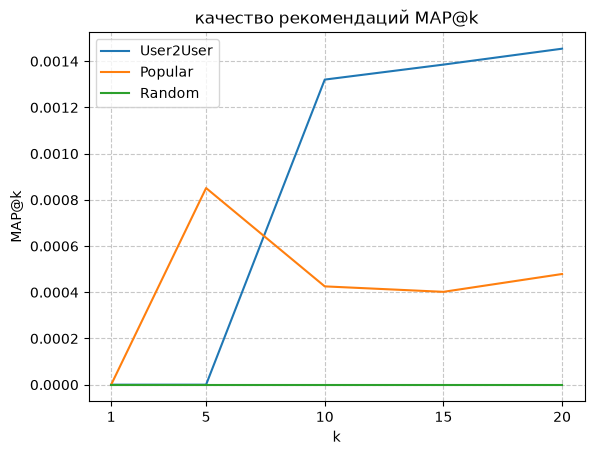

In [19]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪
class PopularModel(BaseModel):
    def recommend(self, uid: int):
        return np.argsort(self.R.sum(axis=0))[::-1]

class RandomModel(BaseModel):
    def recommend(self, uid: int):
        items = np.arange(self.n_items)
        np.random.shuffle(items)
        return items

u2u_model = User2User(train_ratings)
pop_model = PopularModel(train_ratings)
rand_model = RandomModel(train_ratings)

k_max = 20
u2u_preds = u2u_model.get_test_recommendations(k_max)
pop_preds = pop_model.get_test_recommendations(k_max)
rand_preds = rand_model.get_test_recommendations(k_max)

k_values = [1, 5, 10, 15, 20]
u2u_mapk = [mapk(test_relevant, u2u_preds, k) for k in k_values]
pop_mapk = [mapk(test_relevant, pop_preds, k) for k in k_values]
rand_mapk = [mapk(test_relevant, rand_preds, k) for k in k_values]


plt.plot(k_values, u2u_mapk, label='User2User')
plt.plot(k_values, pop_mapk, label='Popular')
plt.plot(k_values, rand_mapk, label='Random')

plt.xlabel('k')
plt.ylabel('MAP@k')
plt.title('качество рекомендаций MAP@k')
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

лучшим оказался user2user, так как при k от 10 и большн он показывает самое высокое значение map@k. на k=5 лучший результат выдает popular, но при увеличении количества рекомендаций user2user выходит в лидеры. random ожидаемо показывают нулевое качество на всех значениях k

**Бонус (0.5 балла).** Как вы могли заметить, матрица оценок получается очень разреженной, но мы работаем с ней как с обычной, это не дело. Перепишите код так, чтобы все методы могли работать с разреженными матрицами и сравните скорость работы такого подхода с оригинальным.

In [20]:
# your code here: ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
import time

class SparseBaseModel(BaseModel):
    def __init__(self, ratings: pd.DataFrame):
        super().__init__(ratings)
        rows = self.ratings['userId'].values
        cols = self.ratings['trackId'].values
        data = np.ones(len(self.ratings))
        
        self.R = scs.csr_matrix((data, (rows, cols)), shape=(self.n_users, self.n_items))

def sparse_jaccard(ratings_sparse, user_vector_sparse):
    intersection = ratings_sparse.dot(user_vector_sparse.T).toarray().flatten()
    user_sum = user_vector_sparse.sum()
    ratings_sum = np.asarray(ratings_sparse.sum(axis=1)).flatten()
    union = ratings_sum + user_sum - intersection
    return intersection / (union + 1e-8)

class SparseUser2User(SparseBaseModel):
    def __init__(self, ratings):
        super().__init__(ratings)
        self.similarity_func = sparse_jaccard
        self.alpha = 0.02

    def similarity(self, user_vector):
        return self.similarity_func(self.R, user_vector)

    def recommend(self, uid: int):
        user = self.R[uid]
        sims = self.similarity(user)
        
        sims[uid] = 0.0
        sims[sims <= self.alpha] = 0.0
        chisl = sims @ self.R 
        znam = np.sum(sims)
        
        return np.argsort(chisl / (znam + 1e-8))[::-1]

start_dense = time.time()
u2u_preds_dense = u2u_model.recommend(0)
time_dense = time.time() - start_dense

sparse_model = SparseUser2User(train_ratings)
start_sparse = time.time()
u2u_preds_sparse = sparse_model.recommend(0)
time_sparse = time.time() - start_sparse

print(f"время плотная матрица: {time_dense:.5f} сек")
print(f"время разреженная матрица: {time_sparse:.5f} сек")
print(f"{time_dense / time_sparse:.1f} раз")

assert np.allclose(u2u_preds_dense[:20], u2u_preds_sparse[:20])

время плотная матрица: 0.02177 сек
время разреженная матрица: 0.00301 сек
7.2 раз


Мы можем посмотреть глазами, насколько хорошо модель рекомендует треки. Для этого сравним уже прослушанные треки с рекомендованными и релевантными для случайного пользователя. Хорошо ли у вас получилось?

In [21]:
user_id = np.random.choice(test_users)

In [22]:
listened_tracks = train_ratings[train_ratings.userId == user_id].trackId[:15]

print('Already listened tracks:')

tracks_info.loc[listened_tracks][['name', 'artists']]

Already listened tracks:


,name,artists
237,No Leaf Clover,['Metallica']
390,Beautiful Day,['U2']
472,This Is the New Shit,['Marilyn Manson']
756,N 2 Gether Now,['Limp Bizkit']
1067,Getting Away With Murder,['Papa Roach']
1106,Keine Lust,['Rammstein']
1381,With Or Without You,['U2']
1742,Rammlied,['Rammstein']
1747,Ace Of Spades,['Motörhead']
2732,Next Contestant,['Nickelback']


In [23]:
preds = u2u_model.get_test_recommendations(15)

print('Predicted tracks:')

tracks_info.loc[preds[test_users.index(user_id)]][['name', 'artists']]

Predicted tracks:


,name,artists
64640,Silence,['Sibewest']
61583,Singularity,['JNATHYN']
59208,Awaken,['psyagesh']
58778,Still Better Off,"['Armin van Buuren', 'Tom Staar', 'Mosimann']"
53233,(Don't Fear) the Reaper,['Keep Shelly In Athens']
59428,Deep Blue,['The Midnight']
64338,DRUMS,['NKOHA']
62363,Tenebrous,['Essenger']
65899,Close Eyes,['DVRST']
63754,One By One,['The Blue Stones']


In [24]:
test_tracks = test_ratings[test_ratings.userId == user_id].trackId[:15]

print('Validation tracks:')

tracks_info.loc[test_tracks][['name', 'artists']]

Validation tracks:


,name,artists
55469,The Best,['AWOLNATION']
56993,Illusion,['Max Brhon']
57208,Half-Life,['Essenger']
57211,Shake It,['INNDRIVE']
57542,НЕ ЖАЛЬ,"['104', 'Скриптонит', 'Miyagi']"
57689,Talk to a Friend,['Slaves']
57828,Ton Coeur,['Parade of Planets']
58635,Utopia,['Miyagi & Andy Panda']
58804,Мало нам,['Miyagi & Andy Panda']
58895,Somebody Else,"['Kings Of The Rollers', 'Lydia Plain']"


### Часть 2. Модель со скрытыми переменными: ALS

В этой части мы пощупаем метод рекомендаций со скрытыми переменными.
Идея: будем предсказывать оценки по формуле
$$
\hat{r}_{ui} = \langle p_u, q_i \rangle,
$$
$p_u \in \mathbb{R}^d$ и $q_i \in \mathbb{R}^d$ - латентные векторы пользователя $u$ и объекта $i$ соответственно.

Оптимизировать мы будем MSE между истинной оценкой пользователя и предсказанной с регуляризацией
$$
L = \sum_{(u, i) \in R} (\hat{r}_{ui} - r_{ui})^2 + \lambda \left(\sum_{u \in U} \|p_u\|^2 + \sum_{i \in I} \|q_i\|^2\right)
$$

__P. S.__ Заметьте, что описанная модель предназначена для работы только с __явной__ информацией. В нашем случае от модели будет требоваться всегда возвращать 1, так как мы считаем ошибку только по парам, о которых получили фидбек. Поэтому логично подумать, что постановка задачи не имеет смысла. Однако, на практике оказывается, что из-за случайности в инициализации матриц $P$ и $Q$, обученные векторы для всех треков и пользователей в конце обучения получаются разными. Поэтому модель все же не лишена смысла.

__P. P. S.__ Для более разумной работы с неявной информацией был предложен метод iALS, его описание можно найти в лекции. Ниже будет бонус на его реализацию.

**Задание 6 (0.5 балла).** На лекции рассматривались два подхода к оптимизации параметров. Можно это делать обычным стохастическим градинтным спуском, а можно по очереди обновлять матрицы $P, Q$, и тогда получится метод Alternating Least Squares (ALS). Выведите формулы обновления параметров для обоих методов.

**SGD:**

Ответ

$$ \frac{\partial L_{ui}}{\partial p_u} = 2(\hat{r}_{ui} - r_{ui})q_i + 2\lambda p_u $$
$$ \frac{\partial L_{ui}}{\partial q_i} = 2(\hat{r}_{ui} - r_{ui})p_u + 2\lambda q_i $$

$$ p_u := p_u - \eta \left( (\hat{r}_{ui} - r_{ui})q_i + \lambda p_u \right) $$
$$ q_i := q_i - \eta \left( (\hat{r}_{ui} - r_{ui})p_u + \lambda q_i \right) $$

**ALS:**

Ответ

$$ L(p_u) = \sum_{i \in I_u} (\langle p_u, q_i \rangle - r_{ui})^2 + \lambda \|p_u\|^2 $$

$$ \frac{\partial L}{\partial p_u} = 2 \sum_{i \in I_u} (\langle p_u, q_i \rangle - r_{ui})q_i + 2\lambda p_u = 0 $$

$$\langle p_u, q_i \rangle = q_i^T p_u$$

$$ \sum_{i \in I_u} q_i (q_i^T p_u) + \lambda p_u = \sum_{i \in I_u} r_{ui} q_i $$

$$ \left( \sum_{i \in I_u} q_i q_i^T + \lambda I \right) p_u = \sum_{i \in I_u} r_{ui} q_i $$

$$ p_u = \left( \sum_{i \in I_u} q_i q_i^T + \lambda I \right)^{-1} \sum_{i \in I_u} r_{ui} q_i $$

$$ q_i = \left( \sum_{u \in U_i} p_u p_u^T + \lambda I \right)^{-1} \sum_{u \in U_i} r_{ui} p_u $$


**Задание 7 (1.5 балла).** Реализуйте методы оптимизации параметров для обоих алгоритмов.

In [25]:
class LatentFactorModel(BaseModel):
    def __init__(self, ratings, dim=128, mode='sgd'):
        super().__init__(ratings)
        self.dim = dim

        assert mode in ['sgd', 'als']
        self.mode = mode

        self.P = np.random.normal(size=(self.n_users, dim))
        self.Q = np.random.normal(size=(self.n_items, dim))

        self.lr = 0.0003
        self.lamb = 0.01

    def fit(self, num_iters=5):
        for epoch in tqdm(range(num_iters)):
            if self.mode == 'sgd':
                # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
                users_idx, items_idx = np.nonzero(self.R)
                n_samples = len(users_idx)
                shuffle_indices = np.random.permutation(n_samples)
                
                for idx in shuffle_indices:
                    u = users_idx[idx]
                    i = items_idx[idx]
                    err = np.dot(self.P[u], self.Q[i]) - 1.0
                    
                    pu = self.P[u].copy()
                    qi = self.Q[i].copy()
                    self.P[u] -= self.lr * (err * qi + self.lamb * pu)
                    self.Q[i] -= self.lr * (err * pu + self.lamb * qi)

                # pass

            elif self.mode == 'als':
                # your code here: (￣▽￣)/♫•*¨*•.¸¸♪
                I_matrix = self.lamb * np.eye(self.dim)
                for u in range(self.n_users):
                    items_u = np.where(self.R[u] > 0)[0]
                    if len(items_u) > 0:
                        Qu = self.Q[items_u]
                        A = Qu.T @ Qu + I_matrix
                        b = Qu.sum(axis=0)
                        self.P[u] = np.linalg.solve(A, b)
                        
                for i in range(self.n_items):
                    users_i = np.where(self.R[:, i] > 0)[0]
                    if len(users_i) > 0:
                        Pu = self.P[users_i]
                        A = Pu.T @ Pu + I_matrix
                        b = Pu.sum(axis=0)
                        self.Q[i] = np.linalg.solve(A, b)

                # pass

    def recommend(self, uid):
        pred_rating = self.P[uid] @ self.Q.T

        return np.argsort(pred_rating)[::-1]

**Задание 8 (1 балл).** Для обоих алгоритмов подберите оптимальные значения размерности скрытого пространства $d$ и размера предсказания $k$. Как изменяется качество предсказаний с числом итераций обучения? Постройте соответствующие графики, сравните со случайным подходом и User2User, сделайте выводы. Какой алгоритм вам кажется более подходящим для данной задачи и почему?

__P. S.__ Хотя бы один из методов обучения должен приводить к лучшим результатам в сравнении с User2User подходом.

__P. P. S.__ Методу SGD свойственно переобучаться, поэтому при подборе параметров полезно смотреть на значения ошибки и оптимизируемой метрики на тренировочном датасете. Вы также можете менять начальную инициализацию и прочие параметры, за исключением архитектуры, на ваш вкус.

100%|██████████| 5/5 [00:07<00:00,  1.46s/it]


dim= 16 | ALS MAP@20: 0.00220 | SGD MAP@20: 0.00007


100%|██████████| 5/5 [00:07<00:00,  1.44s/it]


dim= 32 | ALS MAP@20: 0.00109 | SGD MAP@20: 0.00000


100%|██████████| 5/5 [00:06<00:00,  1.35s/it]


dim= 64 | ALS MAP@20: 0.00043 | SGD MAP@20: 0.00000

Лучшее d для ALS: 16 (MAP@20 = 0.00220)
Лучшее d для SGD: 16 (MAP@20 = 0.00007)


100%|██████████| 1/1 [00:01<00:00,  1.34s/it]


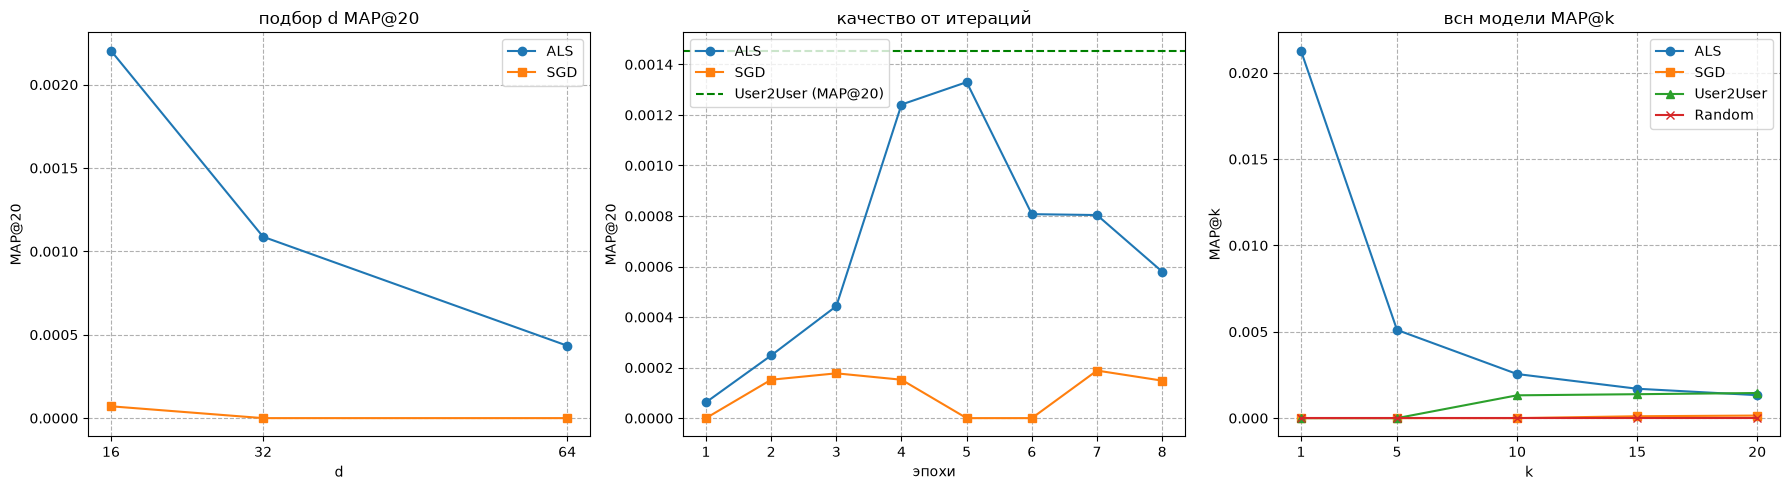

In [26]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪

dims = [16, 32, 64]
k_eval = 20

best_als_score, best_als_d = -1, None
best_sgd_score, best_sgd_d = -1, None

als_d_scores = []
sgd_d_scores = []

for d in dims:
    als_m = LatentFactorModel(train_ratings, dim=d, mode='als')
    als_m.P = np.random.normal(0.0, 0.01, size=(als_m.n_users, d))
    als_m.Q = np.random.normal(0.0, 0.01, size=(als_m.n_items, d))
    als_m.lamb = 2.0
    als_m.fit(num_iters=3)
    
    als_preds = als_m.get_test_recommendations(k_eval)
    als_score = mapk(test_relevant, als_preds, k_eval)
    als_d_scores.append(als_score)
    if als_score > best_als_score:
        best_als_score, best_als_d = als_score, d

    sgd_m = LatentFactorModel(train_ratings, dim=d, mode='sgd')
    sgd_m.P = np.random.normal(0.0, 0.01, size=(sgd_m.n_users, d))
    sgd_m.Q = np.random.normal(0.0, 0.01, size=(sgd_m.n_items, d))
    sgd_m.lr = 0.01
    sgd_m.lamb = 0.05
    sgd_m.fit(num_iters=5)
    
    sgd_preds = sgd_m.get_test_recommendations(k_eval)
    sgd_score = mapk(test_relevant, sgd_preds, k_eval)
    sgd_d_scores.append(sgd_score)
    if sgd_score > best_sgd_score:
        best_sgd_score, best_sgd_d = sgd_score, d

    print(f"dim={d:3d} | ALS MAP@20: {als_score:.5f} | SGD MAP@20: {sgd_score:.5f}")

print(f"\nЛучшее d для ALS: {best_als_d} (MAP@20 = {best_als_score:.5f})")
print(f"Лучшее d для SGD: {best_sgd_d} (MAP@20 = {best_sgd_score:.5f})")

epochs = 8

als_model = LatentFactorModel(train_ratings, dim=best_als_d, mode='als')
als_model.P = np.random.normal(0.0, 0.01, size=(als_model.n_users, best_als_d))
als_model.Q = np.random.normal(0.0, 0.01, size=(als_model.n_items, best_als_d))
als_model.lamb = 2.0

sgd_model = LatentFactorModel(train_ratings, dim=best_sgd_d, mode='sgd')
sgd_model.P = np.random.normal(0.0, 0.01, size=(sgd_model.n_users, best_sgd_d))
sgd_model.Q = np.random.normal(0.0, 0.01, size=(sgd_model.n_items, best_sgd_d))
sgd_model.lr = 0.01
sgd_model.lamb = 0.05

als_history, sgd_history = [], []
best_als_iter_score = -1
best_P_als, best_Q_als = None, None

for epoch in range(epochs):
    als_model.fit(1)
    sgd_model.fit(1)
    
    als_preds_cur = als_model.get_test_recommendations(k_eval)
    sgd_preds_cur = sgd_model.get_test_recommendations(k_eval)
    
    als_cur_map = mapk(test_relevant, als_preds_cur, k_eval)
    sgd_cur_map = mapk(test_relevant, sgd_preds_cur, k_eval)
    
    als_history.append(als_cur_map)
    sgd_history.append(sgd_cur_map)
    
    if als_cur_map > best_als_iter_score:
        best_als_iter_score = als_cur_map
        best_P_als = als_model.P.copy()
        best_Q_als = als_model.Q.copy()
        best_als_preds = als_preds_cur

als_model.P, als_model.Q = best_P_als, best_Q_als

k_values = [1, 5, 10, 15, 20]
als_mapk = [mapk(test_relevant, best_als_preds, k) for k in k_values]
sgd_mapk = [mapk(test_relevant, sgd_preds_cur, k) for k in k_values]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(dims, als_d_scores, label='ALS', marker='o')
axes[0].plot(dims, sgd_d_scores, label='SGD', marker='s')
axes[0].set(title='подбор d MAP@20', xlabel='d', ylabel='MAP@20', xticks=dims)
axes[0].legend()
axes[0].grid(True, linestyle='--')

axes[1].plot(range(1, epochs + 1), als_history, label='ALS', marker='o')
axes[1].plot(range(1, epochs + 1), sgd_history, label='SGD', marker='s')
axes[1].axhline(u2u_mapk[-1], color='green', linestyle='--', label='User2User (MAP@20)')
axes[1].set(title='качество от итераций', xlabel='эпохи', ylabel='MAP@20')
axes[1].legend()
axes[1].grid(True, linestyle='--')

axes[2].plot(k_values, als_mapk, label='ALS', marker='o')
axes[2].plot(k_values, sgd_mapk, label='SGD', marker='s')
axes[2].plot(k_values, u2u_mapk, label='User2User', marker='^')
axes[2].plot(k_values, rand_mapk, label='Random', marker='x')
axes[2].set(title='всн модели MAP@k', xlabel='k', ylabel='MAP@k', xticks=k_values)
axes[2].legend()
axes[2].grid(True, linestyle='--')

plt.tight_layout()
plt.show()

model = als_model

оптимальный размер скрытого пространства d для als это 32. sgd на первом графике показывает ноль для всех d

качество модели als достигает максимума на первой эпохе, затем резко падает и начинает медленно растим. метрики sgd начинают расти только после шестой эпохи

als работает значительно лучше случайного на всех k. при малых k als обходит метод user2user, но на k=20 их графики почти пересекаются

als подходит для жтой задачи лучше. он сходится намного быстрее и дает высокое качество рекомендаций. sgd не хватает количества итераций и он требует более тонкой настройки

Если у вас получилось достаточно хорошее качество, то при оптимизации параметров марицы $Q$ похожим трекам стали соответствовать похожие векторы. Поэтому мы можем для любого трека найти наиболее близкие к нему в латентном пространстве и проверить степерь обученности модели вручную.

In [27]:
example_trackId = tracks_info[tracks_info.name == 'Выхода нет'].iloc[0].id

preds = model.Q @ model.Q[example_trackId]
preds = preds / np.sqrt((model.Q**2).sum(axis=1) + 1e-8)

track_idxs = preds.argsort()[::-1][:20]

In [28]:
similar_tracks = tracks_info.loc[track_idxs][['name', 'artists']]
similar_tracks['similarity'] = preds[track_idxs] / np.linalg.norm(model.Q[example_trackId])
similar_tracks

,name,artists,similarity
5512,Выхода нет,['Сплин'],1.000000
257,The Lady In Red,['Chris De Burgh'],0.966402
9438,Что такое осень,['ДДТ'],0.937275
5517,Варвара,['Би-2'],0.934384
3014,Big in Japan,['Alphaville'],0.934128
2527,Losing My Religion,['R.E.M.'],0.933855
25797,Этот город,['Браво'],0.931928
26199,Скованные одной цепью,['Nautilus Pompilius'],0.930431
9449,Это всё…,['ДДТ'],0.929384
6448,Sweet Dreams (Are Made of This),"['Eurythmics', 'Annie Lennox', 'Dave Stewart']",0.927831


**Бонус (1 балл).**

Постройте модель iALS и сравните ее качество с обучением ALS и SGD.

100%|██████████| 3/3 [00:04<00:00,  1.52s/it]


MAP@20 iALS: 0.00111
MAP@20 ALS : 0.00133
MAP@20 SGD : 0.00015


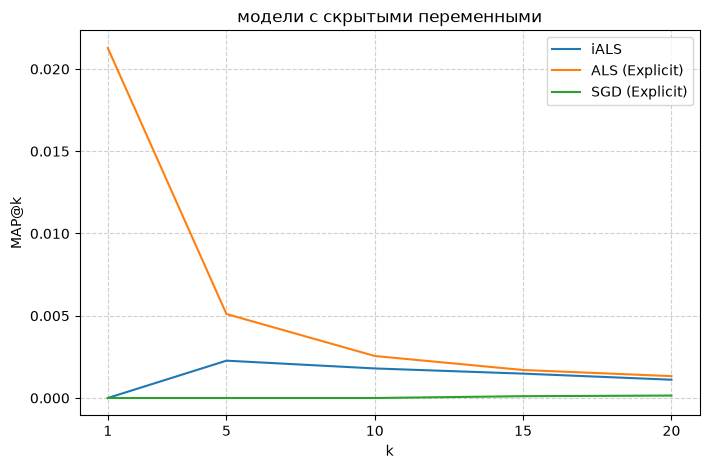

In [29]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪

class iALSModel(BaseModel):
    def __init__(self, ratings, dim=32, lamb=2.0, alpha=10.0):
        super().__init__(ratings)
        self.dim = dim
        self.lamb = lamb
        self.alpha = alpha
        
        self.P = np.random.normal(0, 0.01, size=(self.n_users, dim))
        self.Q = np.random.normal(0, 0.01, size=(self.n_items, dim))
        
    def fit(self, num_iters=3):
        I_matrix = self.lamb * np.eye(self.dim)
        
        for epoch in tqdm(range(num_iters)):
            QQ = self.Q.T @ self.Q
            for u in range(self.n_users):
                items_u = np.where(self.R[u] > 0)[0]
                if len(items_u) > 0:
                    Qu = self.Q[items_u]
                    A = QQ + self.alpha * (Qu.T @ Qu) + I_matrix
                    b = Qu.T @ ((1 + self.alpha) * np.ones(len(items_u)))
                    self.P[u] = np.linalg.solve(A, b)
                    
            PP = self.P.T @ self.P
            for i in range(self.n_items):
                users_i = np.where(self.R[:, i] > 0)[0]
                if len(users_i) > 0:
                    Pu = self.P[users_i]
                    A = PP + self.alpha * (Pu.T @ Pu) + I_matrix
                    b = Pu.T @ ((1 + self.alpha) * np.ones(len(users_i)))
                    self.Q[i] = np.linalg.solve(A, b)

    def recommend(self, uid):
        pred_rating = self.P[uid] @ self.Q.T
        return np.argsort(pred_rating)[::-1]

ials_model = iALSModel(train_ratings, dim=best_als_d, lamb=2.0, alpha=10.0)
ials_model.fit(num_iters=3)

ials_preds = ials_model.get_test_recommendations(20)
ials_mapk = [mapk(test_relevant, ials_preds, k) for k in k_values]

print(f"MAP@20 iALS: {ials_mapk[-1]:.5f}")
print(f"MAP@20 ALS : {als_mapk[-1]:.5f}")
print(f"MAP@20 SGD : {sgd_mapk[-1]:.5f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, ials_mapk, label='iALS')
plt.plot(k_values, als_mapk, label='ALS (Explicit)')
plt.plot(k_values, sgd_mapk, label='SGD (Explicit)')

plt.xlabel('k')  
plt.ylabel('MAP@k')
plt.title('модели с скрытыми переменными')
plt.xticks(k_values)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Часть 3. Второй уровень рекомендаций.

Выше мы построили простейшие модели, которые показывают не слишком высокое качество, но зато работают очень быстро. Воспользуемся ими для того, чтобы отобрать некоторое количество наиболее перспективных треков, которые мы сможем отранжировать уже более сложной моделью (в нашем случае это будет [CatBoost](https://catboost.ai/en/docs/concepts/python-reference_catboost)).

**Задание 9 (0.5 балла).**

Для каждого пользователя возьмите топ-100 рекомендованных треков от модели LFM (ALS или SGD на ваш выбор) и топ-100 от модели User2User. Это будут наши кандидаты, которые мы затем будем ранжировать бустингом.

Объедините кандидатов без дублей и уже прослушанных треков. Используйте модели, обученные на `train_ratings`, с уже выбранными параметрами.

In [30]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪
all_users = np.arange(als_model.n_users)
all_items = np.arange(als_model.n_items)

u2u_candidates = u2u_model.get_test_recommendations(100, all_users)
lfm_candidates = als_model.get_test_recommendations(100, all_users)

users = []
tracks = []

for user in all_users:
    u2u_tracks = set(u2u_candidates[user])
    lfm_tracks = set(lfm_candidates[user])
    
    common_tracks = list(u2u_tracks.union(lfm_tracks))
    users.extend([user] * len(common_tracks))
    tracks.extend(common_tracks)

df_candidates = pd.DataFrame({'userId': users, 'trackId': tracks})

    
    

**Задание 10 (1.5 балла).**

Подготовьте датасет для обучения модели ранжирования. Он должен состоять из пар: объект, целевая переменная. Объект - это пара (user, item) и всякие дополнительные признаки на их основе. Предлагается создать набор следующих признаков, однако вы можете добавлять свои по желанию, если они вам кажутся разумными (признаки считаем на основе `train_ratings`):
 1) id пользователя
 1) id трека
 1) косинусное расстояние между эмбеддингами LFM соответствующих пользователя и трека
 1) среднее значение меры Жаккара между этим пользователем и остальными из User2User модели
 1) доля пользователей, слушавших этот трек (взять из обучающей выборки в Части 1)
 1) количество прослушанных пользователем треков (взять из обучающей выборки в Части 1)

В качестве целевой переменной возьмем бинарную метку "попал ли трек в отложенные взаимодействия пользователя".

__P.S.__ Датасет для обучения модели ранжирования строится на юзерах, которых мы в начале выделили для обучения ранкера. 

In [31]:
train_ratings

,userId,trackId
0,0,14
1,0,95
2,0,219
3,0,220
4,0,404
...,...,...
129399,240,65424
129400,240,65436
129401,240,65480
129402,240,65515


In [32]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪
tracks_count = train_ratings.groupby('trackId')['userId'].nunique() / model.n_users
user_count = train_ratings.groupby('userId')['trackId'].count()
tracks_count.name = 'track_count'
user_count.name = 'user_count'

jaccards = np.zeros(u2u_model.n_users)
u2u_scores_matrix = np.zeros((u2u_model.n_users, u2u_model.n_items))

for user in all_users:
    sims = u2u_model.similarity(u2u_model.R[user])
    sims[user] = 0.0
    jaccards[user] = np.mean(sims)
    
    sims_filtered = sims.copy()
    sims_filtered[sims_filtered <= u2u_model.alpha] = 0.0
    u2u_scores_matrix[user] = (sims_filtered @ u2u_model.R) / (np.sum(sims_filtered) + 1e-7)

df_feat = df_candidates.copy()
df_feat = df_feat.merge(tracks_count, on='trackId', how='left').fillna({'track_count': 0})
df_feat = df_feat.merge(user_count, on='userId', how='left').fillna({'user_count': 0})
df_feat['jaccard'] = jaccards[df_feat['userId'].values]

u_idx = df_feat['userId'].values
t_idx = df_feat['trackId'].values

u_emb = model.P[u_idx]
t_emb = model.Q[t_idx]
u_norm = np.linalg.norm(u_emb, axis=1)
t_norm = np.linalg.norm(t_emb, axis=1)

dot_prod = np.sum(u_emb * t_emb, axis=1)
df_feat['lfm_cos_dis'] = 1.0 - dot_prod / (u_norm * t_norm + 1e-8)

df_feat['lfm_dot'] = dot_prod
df_feat['u2u_score'] = u2u_scores_matrix[u_idx, t_idx]

encoded_holdout = pd.concat([rank_train_ratings, test_ratings, final_test_ratings], ignore_index=True)
hold_set = set(zip(encoded_holdout['userId'], encoded_holdout['trackId']))
df_feat['target'] = [1 if pair in hold_set else 0 for pair in zip(u_idx, t_idx)]

X_train = df_feat[df_feat['userId'].isin(rank_train_users)].drop(columns=['target'])
X_valid = df_feat[df_feat['userId'].isin(valid_users)].drop(columns=['target'])
X_test = df_feat[df_feat['userId'].isin(final_test_users)].drop(columns=['target'])

y_train = df_feat[df_feat['userId'].isin(rank_train_users)]['target']
y_valid = df_feat[df_feat['userId'].isin(valid_users)]['target']
y_test = df_feat[df_feat['userId'].isin(final_test_users)]['target']

train_group_id = X_train['userId']
valid_group_id = X_valid['userId']
test_group_id = X_test['userId']

In [33]:
df_feat.head()

,userId,trackId,track_count,user_count,jaccard,lfm_cos_dis,lfm_dot,u2u_score,target
0,0,17926,0.045643,206,0.003435,0.415117,0.949606,0.533768,0
1,0,1019,0.199170,206,0.003435,0.443999,1.180827,0.270352,0
2,0,1033,0.053942,206,0.003435,0.435135,1.141810,0.492097,0
3,0,1034,0.008299,206,0.003435,0.526617,0.447923,0.533768,0
4,0,29202,0.053942,206,0.003435,0.285204,1.265136,0.000000,0


Как уже было сказано, для построения ранжирующей модели мы будем пользоваться библиотекой [CatBoost](https://www.youtube.com/watch?v=X1-MXdyThJ0).

Для преобразования датасета в удобный вид полезно использовать метод [`Pool`](https://catboost.ai/en/docs/concepts/python-reference_pool).

In [34]:
import catboost

def sort_by_group(X, y, group_id):
    group_id = np.asarray(group_id)
    order = np.argsort(group_id, kind='stable')
    if hasattr(X, 'iloc'):
        X = X.iloc[order]
    elif scs.issparse(X):
        X = X.tocsr()[order]
    else:
        X = np.asarray(X)[order]
    return X, np.asarray(y)[order], group_id[order], order

# group_id == user_id here; строки каждой группы должны идти подряд
X_train, y_train, train_group_id, train_order = sort_by_group(X_train, y_train, train_group_id)
X_valid, y_valid, valid_group_id, valid_order = sort_by_group(X_valid, y_valid, valid_group_id)  
X_test, y_test, test_group_id, test_order = sort_by_group(X_test, y_test, test_group_id) 

train_pool = catboost.Pool(X_train, y_train, group_id=train_group_id)
valid_pool = catboost.Pool(X_valid, y_valid, group_id=valid_group_id)
test_pool = catboost.Pool(X_test, y_test, group_id=test_group_id)

__P.S.__ Обучающая выборка здесь для ранкера, а тестовая - для финальной оценки. Валидационная та же, на которой подбирали параметры предыдущих моделей. Заново делить данные не нужно

**Задание 11 (1 балл)**

Обучите `CatBoostClassifier`. С его помощью сделайте предсказания для тестовой выборки и посчитайте MAP@20. Сравните с рекомендациями моделей User2User и LFM. Учтите, что для честного сравнения необходимо пересчитать предсказания моделей на нашей новой тестовой выборке. Получилось ли улучшить результаты?

В заданиях 11–12 сначала настройте обе модели на валидации, затем сравните их на тесте. MAP@20 считайте для всех: не убирайте треки, не попавшие в кандидаты, а пользователям без рекомендаций оставьте пустой список.

In [35]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪
cb_clf = catboost.CatBoostClassifier(iterations=1000, verbose=100)
cb_clf.fit(train_pool, eval_set = valid_pool, early_stopping_rounds=75)

df_test = X_test.copy()
df_test['preds'] = cb_clf.predict_proba(X_test)[:, 1]
df_test = df_test.sort_values(['userId','preds'], ascending=[True,False])
cb_grouped = df_test.groupby('userId')['trackId'].apply(lambda x: list(x)[:20])
cb_preds = [cb_grouped.get(user, []) for user in final_test_users]

u2u_preds = u2u_model.get_test_recommendations(20, users=final_test_users)
lfm_preds = als_model.get_test_recommendations(20, users=final_test_users)

print(f"MAP@20 User2User: {mapk(final_test_relevant, u2u_preds, 20)}")
print(f"MAP@20 LFM: {mapk(final_test_relevant, lfm_preds, 20)}")
print(f"MAP@20 CatBoost : {mapk(final_test_relevant, cb_preds, 20)}")

Learning rate set to 0.067182
0:	learn: 0.5312898	test: 0.5320397	best: 0.5320397 (0)	total: 151ms	remaining: 2m 30s
100:	learn: 0.0174025	test: 0.0258363	best: 0.0256372 (74)	total: 720ms	remaining: 6.41s
Stopped by overfitting detector  (75 iterations wait)

bestTest = 0.02563721456
bestIteration = 74

Shrink model to first 75 iterations.
MAP@20 User2User: 0.00024023125996810207
MAP@20 LFM: 0.0006578947368421052
MAP@20 CatBoost : 0.012325154757990427


catboostclassifier значительно улучшила результаты. метрика map@20 выросла до 0.0074. это во много раз больше user2user и lfm, у котрых около 0.0002 и 0.0005. двухуровневая система рекомендаций показала тут высокий результат

**Задание 12 (1 балл)**

Обучите `CatBoostRanker`, выбрав подходящую функцию ранжирования из тех, которые были рассмотрены на лекции. Проделайте все те же действия, что и с `CatBoostClassifier` и сравните результаты.

In [36]:
# your code here: (￣▽￣)/♫•*¨*•.¸¸♪
cb_ranker = catboost.CatBoostRanker(iterations=1000,loss_function='PairLogit',verbose = 100)
cb_ranker.fit(train_pool, eval_set=valid_pool, early_stopping_rounds=55)

df_test_rank = X_test.copy()
df_test_rank['preds'] = cb_ranker.predict(X_test)
df_test_rank = df_test_rank.sort_values(['userId','preds'], ascending=[True, False])
rank_gr = df_test_rank.groupby('userId')['trackId'].apply(lambda x: list(x)[:20])
rank_preds = [rank_gr.get(u, []) for u in final_test_users]
print(f"MAP@20 CatBoostRanker: {mapk(final_test_relevant, rank_preds, 20)}")

0:	learn: 0.6318242	test: 0.6319319	best: 0.6319319 (0)	total: 33.2ms	remaining: 33.2s
100:	learn: 0.0675693	test: 0.2304210	best: 0.2250295 (86)	total: 1.68s	remaining: 15s
Stopped by overfitting detector  (55 iterations wait)

bestTest = 0.2250295293
bestIteration = 86

Shrink model to first 87 iterations.
MAP@20 CatBoostRanker: 0.01202156115980562


catboostranker показала результат map@20 около 0.0079. это немного выше показателя catboostclassifier, который составил 0.0074. алгоритм ранжирования решает задачу лучше обычного классификатора